# 03 – Self-supervised training and anomaly detection

* **Model:** `Linear(17 → 32)` → 2 × Mamba (d_state 16) → `Linear(32 → 7)`.
* **Objective:** next-step prediction on **nominal** windows only (the output at time t predicts the signals at t+1 — not identity reconstruction, which a residual network could solve trivially).
* **Score:** `s_t` = squared next-step prediction error (mean over observed channels, z-units).
* **Threshold:** 99th percentile of `s_t` on **nominal validation** points.
* **Metrics:** point-wise *and* event-wise P / R / F1 / AUROC / AUPRC (point-adjust shown only as a reference).

**Setup.** *Expected output:* project root and versions.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "font.size": 9})

print("project root:", ROOT)
print("torch", torch.__version__, "| numpy", np.__version__)

project root: D:\Project\Development\Mamba_CubeSat
torch 2.15.0+cpu | numpy 2.5.4


## 1. Seeds, device and hyper-parameters
Everything runs on CPU; set `USE_GPU = True` later to move to CUDA (the code is device-agnostic).
`EPOCHS` is kept small for a CPU run — raise it on GPU.
*Expected output:* the device (`cpu`) and the hyper-parameters.

In [2]:
from src import data, metrics
from src.models import MambaForecaster
from src.mamba import count_parameters
from src.train import (set_seed, get_device, make_loader, next_step_loss, overfit_single_batch,
                       fit, load_checkpoint, predict_series, anomaly_scores)

SEED = 0
USE_GPU = False
set_seed(SEED)
device = get_device(USE_GPU)

HP = dict(window=512, batch_size=32, d_model=32, n_layers=2, d_state=16,
          lr=1e-3, weight_decay=1e-2, clip=1.0, epochs=12, patience=4)
CKPT = ROOT / "checkpoints" / "mamba_forecaster_best.pt"
print("device:", device)
print(HP)

device: cpu
{'window': 512, 'batch_size': 32, 'd_model': 32, 'n_layers': 2, 'd_state': 16, 'lr': 0.001, 'weight_decay': 0.01, 'clip': 1.0, 'epochs': 12, 'patience': 4}


## 2. Data
Re-create exactly the dataset from notebook 01 (same seed → same arrays).
*Expected output:* `train windows (W, 512, 17)` with 0 anomalous points, plus the val windows.

In [3]:
raw, proc = data.build_dataset(data.TelemetryConfig(seed=SEED), window=HP["window"])
trw, vaw = proc["train_windows"], proc["val_windows"]
print("train windows X", trw["X"].shape, "Y", trw["Y"].shape, "M", trw["M"].shape)
print("val   windows X", vaw["X"].shape)
assert trw["labels"].sum() == 0 and vaw["labels"].sum() == 0, "training data must be nominal"
IN_CH, OUT_CH = trw["X"].shape[-1], trw["Y"].shape[-1]
print("in_channels", IN_CH, "| out_channels", OUT_CH)

train windows X (282, 512, 17) Y (282, 512, 7) M (282, 512, 7)
val   windows X (21, 512, 17)
in_channels 17 | out_channels 7


## 3. Data loaders
Shuffled training loader (seeded generator), unshuffled validation loader.
*Expected output:* number of batches and one batch's shapes `(32, 512, 17)`, `(32, 512, 7)`, `(32, 512, 7)`.

In [4]:
train_loader = make_loader(trw, HP["batch_size"], shuffle=True, seed=SEED)
val_loader = make_loader(vaw, HP["batch_size"], shuffle=False)
xb, yb, mb = next(iter(train_loader))
print("batches: train", len(train_loader), "| val", len(val_loader))
print("batch:", tuple(xb.shape), tuple(yb.shape), tuple(mb.shape), xb.dtype)
assert xb.shape[1:] == (HP["window"], IN_CH)

batches: train 9 | val 1
batch: (32, 512, 17) (32, 512, 7) (32, 512, 7) torch.float32


## 4. Model and a first forward pass
*Expected output:* ≈ 21 k parameters, output shape `(32, 511, 7)` (input is `x[:, :-1]`), and an initial loss around 1 (targets are z-scored).

In [5]:
set_seed(SEED)
model = MambaForecaster(IN_CH, OUT_CH, d_model=HP["d_model"], n_layers=HP["n_layers"],
                        d_state=HP["d_state"]).to(device)
print(f"parameters: {count_parameters(model):,}")
with torch.no_grad():
    out = model(xb[:, :-1].to(device))
    loss0 = next_step_loss(model, xb.to(device), yb.to(device), mb.to(device)).item()
print("output:", tuple(out.shape), "| initial loss:", round(loss0, 4))
assert out.shape == (xb.shape[0], xb.shape[1] - 1, OUT_CH) and torch.isfinite(out).all()

parameters: 20,839


output: (32, 511, 7) | initial loss: 1.4526


## 5. Baseline: persistence forecast
A model that predicts `ŷ_{t+1} = y_t` needs no training. The Mamba model must beat this, otherwise it has learned nothing beyond "the signal is smooth".
*Expected output:* the persistence MSE on the validation windows (the trained model should end below it).

In [6]:
def persistence_mse(w):
    pred, tgt, valid = w["Y"][:, :-1], w["Y"][:, 1:], 1 - w["M"][:, 1:]
    return float(((pred - tgt) ** 2 * valid).sum() / valid.sum())

persist_val = persistence_mse(vaw)
print(f"persistence val MSE: {persist_val:.4f}")

persistence val MSE: 0.1373


## 6. Sanity check: overfit a single batch
A fresh model trained only on 4 short windows should drive its loss far below the starting value. If it can't, there is a bug in the model, loss or data alignment.
*Expected output:* the loss falls by well over an order of magnitude within 300 steps.

step    0  loss 1.39532


step   50  loss 0.07594


step  100  loss 0.06173


step  150  loss 0.04746


step  200  loss 0.03209


step  250  loss 0.01841


step  299  loss 0.01002
final / initial loss = 0.0072


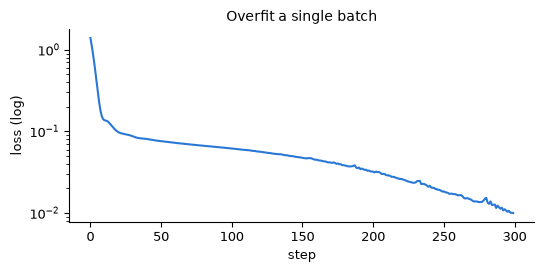

In [7]:
set_seed(SEED)
tiny = MambaForecaster(IN_CH, OUT_CH, d_model=HP["d_model"], n_layers=HP["n_layers"],
                       d_state=HP["d_state"]).to(device)
one_batch = (xb[:4, :128], yb[:4, :128], mb[:4, :128])
losses = overfit_single_batch(tiny, one_batch, steps=300, lr=3e-3, device=device, log_every=50)
ratio = losses[-1] / losses[0]
print(f"final / initial loss = {ratio:.4f}")
assert ratio < 0.1, "model failed to overfit one batch - check the pipeline"

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.semilogy(losses, color=data.SERIES_COLOR, lw=1.5)
ax.set_xlabel("step"); ax.set_ylabel("loss (log)"); ax.set_title("Overfit a single batch")
ax.spines[["top", "right"]].set_visible(False); plt.show()
del tiny

## 7. Train
AdamW (lr 1e-3, weight decay 1e-2), gradient-norm clipping at 1.0, early stopping on the validation loss. The best checkpoint is saved to `checkpoints/`.
*Expected output:* one line per epoch; the train and val loss decrease and `* saved` marks improvements. On CPU each epoch takes roughly 10–40 s.

In [8]:
set_seed(SEED)
history = fit(model, train_loader, val_loader, epochs=HP["epochs"], lr=HP["lr"],
              weight_decay=HP["weight_decay"], clip=HP["clip"], ckpt_path=CKPT,
              patience=HP["patience"], device=device)
print(f"best val loss {history['best_val']:.4f} at epoch {history['best_epoch']} "
      f"(persistence {persist_val:.4f})")

epoch   1 | train 1.1223 | val 0.7286 |  21.9s  * saved


epoch   2 | train 0.4950 | val 0.2572 |  20.6s  * saved


epoch   3 | train 0.1810 | val 0.1389 |  21.5s  * saved


epoch   4 | train 0.1256 | val 0.1114 |  15.2s  * saved


epoch   5 | train 0.1038 | val 0.0973 |  15.9s  * saved


epoch   6 | train 0.0951 | val 0.0905 |  17.0s  * saved


... (2 outputs left out)

epoch   9 | train 0.0837 | val 0.0819 |  14.8s  * saved


epoch  10 | train 0.0819 | val 0.0802 |  14.5s  * saved


epoch  11 | train 0.0805 | val 0.0789 |  16.1s  * saved


epoch  12 | train 0.0793 | val 0.0777 |  15.5s  * saved
best val loss 0.0777 at epoch 12 (persistence 0.1373)


## 8. Loss curves
*Expected output:* both curves decreasing; the dashed line is the persistence baseline.

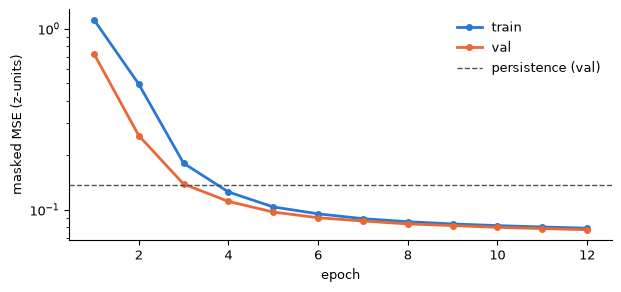

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history["epoch"], history["train_loss"], color="#2a78d6", lw=2, marker="o", ms=4, label="train")
ax.plot(history["epoch"], history["val_loss"], color="#eb6834", lw=2, marker="o", ms=4, label="val")
ax.axhline(persist_val, color="#52514e", ls="--", lw=1, label="persistence (val)")
ax.set_xlabel("epoch"); ax.set_ylabel("masked MSE (z-units)"); ax.set_yscale("log")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); plt.show()

## 9. Load the best checkpoint
*Expected output:* the epoch and val loss stored in the checkpoint; it beats persistence.

In [10]:
ckpt = load_checkpoint(CKPT, model, device)
print("loaded epoch", ckpt["epoch"], "| val loss", round(ckpt["val_loss"], 4), "| config", ckpt["config"])
assert ckpt["val_loss"] < persist_val, "model should beat the persistence baseline"

loaded epoch 12 | val loss 0.0777 | config {'in_channels': 17, 'out_channels': 7, 'd_model': 32, 'n_layers': 2, 'd_state': 16, 'd_conv': 4, 'expand': 2}


## 10. Score the full validation and test series
`predict_series` slides overlapping 512-step windows over each contiguous split (each window discards its first 128 outputs as state warm-up, so every step is predicted exactly once). Then `s_t` = mean squared error over observed channels.
*Expected output:* score arrays with the length of each split, all finite and ≥ 0.

In [11]:
scores, chan_err = {}, {}
for name in ("val", "test"):
    s = proc[name]
    preds = predict_series(model, s["X"], window=HP["window"], warmup=128, device=device)
    scores[name], chan_err[name] = anomaly_scores(preds, s["Y"], s["M"])
    print(f"{name:5s} preds {preds.shape}  scores {scores[name].shape}  "
          f"median {np.median(scores[name]):.4f}  max {scores[name].max():.2f}")
    assert len(scores[name]) == len(s["X"]) and np.isfinite(scores[name]).all()
    assert (scores[name] >= 0).all()

val   preds (8208, 7)  scores (8208,)  median 0.0620  max 12.48


test  preds (8208, 7)  scores (8208,)  median 0.0784  max 11.32


## 11. Threshold from nominal validation scores
`τ` = 99th percentile of the scores on validation points labelled nominal. By construction ≈1 % of nominal validation points exceed it.
*Expected output:* τ and a nominal false-positive rate of ~1 % on val (and similar on test).

In [12]:
thr = metrics.threshold_from_nominal(scores["val"], proc["val"]["labels"], q=99)
for name in ("val", "test"):
    nom = proc[name]["labels"] == 0
    print(f"{name:5s} nominal FPR at tau: {(scores[name][nom] > thr).mean():.3%}")
print(f"tau = {thr:.4f}")

val   nominal FPR at tau: 1.007%


test  nominal FPR at tau: 2.082%
tau = 0.3251


## 12. Metrics – point-wise and event-wise
See the docstring of `src/metrics.py` for the exact definitions. Event precision counts each contiguous false-alarm episode once.
*Expected output:* a table for val and test. Point-wise recall is limited by the long collective event (most of its points look normal one step ahead), whereas event-wise recall reflects how many *incidents* were caught. The point-adjusted F1 is printed only to show how optimistic it is.

In [13]:
reports = {}
for name in ("val", "test"):
    s = proc[name]
    reports[name] = metrics.full_report(scores[name], s["labels"], s["event_id"], thr)
    print(metrics.format_report(reports[name], name))
    print("event recall by type:",
          metrics.per_type_recall(reports[name]["event"]["per_event"], raw["events"]), "\n")

=== val  (threshold = 0.3251) ===
                   P       R      F1   AUROC   AUPRC
point-wise     0.585   0.679   0.628   0.983   0.670
event-wise     0.168   1.000   0.288   1.000   0.873
events detected 16/16, false-alarm episodes 79, composite F1 0.738
(reference only) point-adjusted F1 0.806
event recall by type: {'point': '11/11', 'contextual': '5/5'} 

=== test  (threshold = 0.3251) ===
                   P       R      F1   AUROC   AUPRC
point-wise     0.787   0.177   0.289   0.688   0.554
event-wise     0.200   1.000   0.333   1.000   0.962
events detected 29/29, false-alarm episodes 116, composite F1 0.881
(reference only) point-adjusted F1 0.977
event recall by type: {'point': '22/22', 'contextual': '6/6', 'collective': '1/1'} 



## 12b. Reference: a random scorer
Uniform random scores, thresholded the same way (99th pct of nominal val). This is the floor every metric should be compared against.
*Expected output:* point-wise AUROC ≈ 0.5 and tiny F1 — but a **high point-adjusted F1**, which is exactly why PA alone is misleading. Event AUROC is also above 0.5 for random scores, because long events are easy to "hit" by chance.

In [14]:
rng = np.random.default_rng(SEED)
rand = {n: rng.random(len(proc[n]["labels"])) for n in ("val", "test")}
thr_r = metrics.threshold_from_nominal(rand["val"], proc["val"]["labels"], q=99)
rep_r = metrics.full_report(rand["test"], proc["test"]["labels"], proc["test"]["event_id"], thr_r)
print(metrics.format_report(rep_r, "test, RANDOM scorer"))

=== test, RANDOM scorer  (threshold = 0.9912) ===
                   P       R      F1   AUROC   AUPRC
point-wise     0.297   0.011   0.021   0.496   0.299
event-wise     0.045   0.103   0.062   0.729   0.042
events detected 3/29, false-alarm episodes 64, composite F1 0.153
(reference only) point-adjusted F1 0.944


## 13. Scores vs. ground truth (whole test split)
Top: battery voltage (z) for orientation. Bottom: anomaly score (log scale) with the threshold; red bands are labelled anomalies.
*Expected output:* sharp score peaks at point and contextual events; the collective fade at the end shows a gradual rise rather than a sharp peak.
Note: after a spike, the model's *next* prediction is also off (the spike is in its input), so the sample just after a spike often scores high but is labelled nominal → it counts as a false-alarm episode. This is inherent to next-step prediction and partly explains the low event precision.

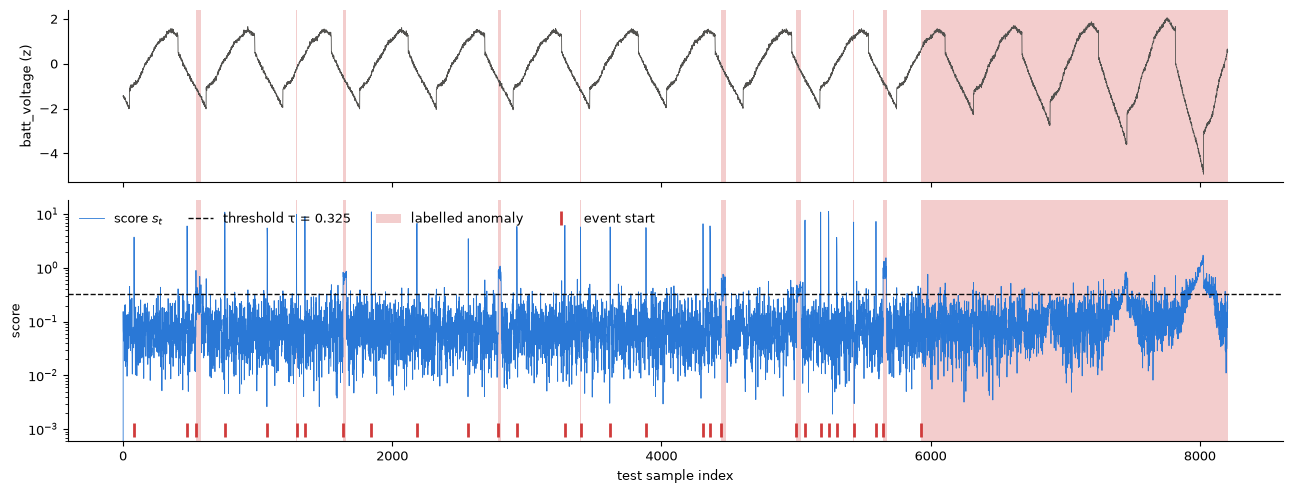

In [15]:
te = proc["test"]
x = np.arange(len(te["X"]))
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
axes[0].plot(x, te["Y"][:, 0], color="#52514e", lw=0.6)
axes[0].set_ylabel("batt_voltage (z)")
axes[1].plot(x, scores["test"], color=data.SERIES_COLOR, lw=0.6, label="score $s_t$")
axes[1].axhline(thr, color="#0b0b0b", ls="--", lw=1, label=f"threshold τ = {thr:.3f}")
axes[1].set_yscale("log"); axes[1].set_ylabel("score"); axes[1].set_xlabel("test sample index")
for ax in axes:
    data.shade_spans(ax, te["labels"], data.ANOM_COLOR, 0.25, "labelled anomaly")
    ax.spines[["top", "right"]].set_visible(False)
# 1-2 sample events are too thin to see as bands -> add tick marks under the score axis
starts = [s for s, e, _ in metrics.events_from_ids(te["event_id"])]
axes[1].plot(starts, np.full(len(starts), scores["test"][scores["test"] > 0].min() * 0.5), "|",
             color=data.ANOM_COLOR, ms=10, mew=2, label="event start")
axes[1].legend(frameon=False, loc="upper left", ncol=4)
fig.tight_layout(); plt.show()

## 14. Zoom on one event of each type
*Expected output:* three panels — a spike crossing τ immediately; a contextual event (solar current/temperature in eclipse) producing a sustained score elevation; the onset of the collective fade.

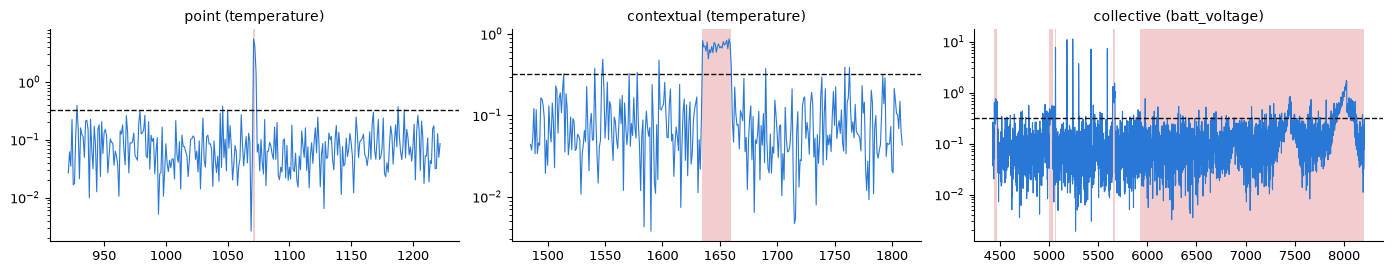

In [16]:
off = proc["splits"]["test"].start
test_events = [e for e in raw["events"] if e["start"] >= off]
pick = {}
for e in test_events:
    pick.setdefault(e["kind"], e)
fig, axes = plt.subplots(1, len(pick), figsize=(14, 2.8))
for ax, (kind, e) in zip(np.atleast_1d(axes), pick.items()):
    s, en = e["start"] - off, e["end"] - off
    pad = 1500 if kind == "collective" else 150
    sl = slice(max(0, s - pad), min(len(te["X"]), en + (150 if kind != "collective" else 0)))
    xx = np.arange(sl.start, sl.stop)
    ax.plot(xx, scores["test"][sl], color=data.SERIES_COLOR, lw=0.8)
    ax.axhline(thr, color="#0b0b0b", ls="--", lw=1)
    data.shade_spans(ax, te["labels"][sl], data.ANOM_COLOR, 0.25, x0=sl.start)
    ax.set_yscale("log"); ax.set_title(f"{kind} ({e['channel']})")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 15. Which channel drives the score in the collective event?
Mean per-channel squared error during the fade vs. nominal test points. This is a quick explainability check: the battery-voltage channel should dominate.
*Expected output:* a bar chart where `batt_voltage` has the largest ratio.

batt_voltage    51.28x
solar_current    1.36x
temperature      1.15x
omega_x          1.13x
omega_y          1.10x
omega_z          1.18x
rssi             1.13x


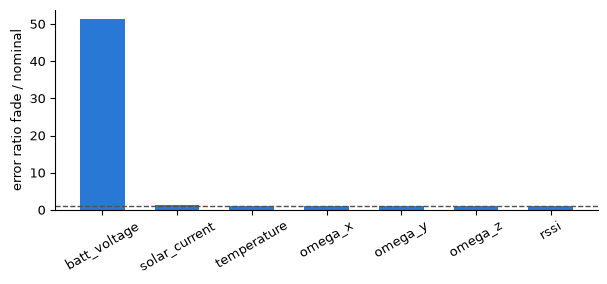

In [17]:
fade = next(e for e in raw["events"] if e["kind"] == "collective")
in_fade = te["event_id"] == fade["id"]
nom = te["labels"] == 0
ratio = chan_err["test"][in_fade].mean(0) / chan_err["test"][nom].mean(0)
for n_, r_ in zip(proc["names"], ratio):
    print(f"{n_:14s} {r_:6.2f}x")
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(proc["names"], ratio, color=data.SERIES_COLOR, width=0.6)
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_ylabel("error ratio fade / nominal"); ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=30); plt.show()

## 16. Optional: smoothed score
Single-step errors are good for spikes but weak for slow, collective drifts. A causal moving average over one eclipse (210 samples) of `s_t` is a cheap way to accumulate evidence. The threshold is recomputed the same way (99th pct of smoothed nominal validation scores).
*Expected output:* the same metric tables for the smoothed score. It is a **trade-off**: alarms become sustained, so there are far fewer false-alarm episodes (higher event precision) and the collective fade is still caught, but short spikes are diluted by the average and most point/contextual events are missed. This is a design choice to discuss in the thesis (e.g. combining raw and smoothed scores), not a replacement for the raw score.

In [18]:
def causal_ma(s, k):
    c = np.cumsum(np.r_[0.0, s])
    out = (c[k:] - c[:-k]) / k
    return np.r_[c[1:k] / np.arange(1, k), out]

K = 210
sm = {n: causal_ma(scores[n], K) for n in ("val", "test")}
thr_sm = metrics.threshold_from_nominal(sm["val"], proc["val"]["labels"], q=99)
rep_sm = metrics.full_report(sm["test"], te["labels"], te["event_id"], thr_sm)
print(metrics.format_report(rep_sm, f"test, causal MA({K})"))
print("event recall by type:", metrics.per_type_recall(rep_sm["event"]["per_event"], raw["events"]))
assert len(sm["test"]) == len(scores["test"])

=== test, causal MA(210)  (threshold = 0.2193) ===
                   P       R      F1   AUROC   AUPRC
point-wise     0.466   0.163   0.241   0.494   0.377
event-wise     0.348   0.276   0.308   0.711   0.471
events detected 8/29, false-alarm episodes 15, composite F1 0.347
(reference only) point-adjusted F1 0.885
event recall by type: {'point': '5/22', 'contextual': '2/6', 'collective': '1/1'}


## 17. Streaming inference with `step()`
On board, telemetry arrives one sample at a time. Run the trained model with `step()` over the first 300 test samples and compare to the batched `forward()` on the same samples.
*Expected output:* max difference < 1e-5 and the per-sample latency on CPU.

In [19]:
import time
model.eval()
Xs = torch.from_numpy(te["X"][:300]).float().unsqueeze(0).to(device)
with torch.no_grad():
    full = model(Xs)[0]
    states = model.init_state(1, device=device)
    outs, t0 = [], time.time()
    for t in range(Xs.shape[1]):
        y_t, states = model.step(Xs[:, t], states)
        outs.append(y_t[0])
    dt = (time.time() - t0) / Xs.shape[1]
diff = (torch.stack(outs) - full).abs().max().item()
print(f"max |step - forward| = {diff:.2e} | {dt * 1e3:.2f} ms per sample")
assert diff < 1e-5

max |step - forward| = 4.77e-07 | 0.89 ms per sample


## Summary
* The overfitting sanity check passes, and the trained model beats the persistence baseline on validation. With only 12 CPU epochs the validation loss is still falling — train longer on GPU.
* The threshold comes from nominal validation data only; results are reported point-wise and event-wise (point-adjusted F1 for reference only).
* Expected pattern: point and contextual anomalies are detected reliably; the slow capacity fade is the hard case for a one-step-ahead error, which motivates multi-step / smoothed scoring in later experiments.

**Moving to GPU:** set `USE_GPU = True`, increase `epochs`, and later swap `src/mamba.py`'s scan for `mamba-ssm`'s fused kernel — the model interface (`forward`, `step`) stays the same.